# 03 · Modelo supervisado: regresión del consumo — Grupo 6 UTS

**Semana 13 · CRISP-DM fases 4 y 5 (Modelado y evaluación del modelo supervisado).**

- **Variable objetivo:** `Appliances`, consumo de los electrodomésticos en Wh cada 10 minutos (variable continua →
  tarea de **regresión**).
- **Predictores:** temperatura de las 9 zonas y humedad de 8 de ellas (`RH_6` se excluyó), clima exterior, hora del día (cíclica) y día de la semana,
  preparados en `02_preparacion.ipynb`.
- **Modelos:** una línea base ingenua, una **regresión Ridge** (lineal, interpretable) y un **Random Forest**
  (no lineal).
- **Evaluación:** MAE, RMSE y R² sobre el 20 % final del periodo (prueba cronológica), en Wh.

> Requiere haber ejecutado antes `02_preparacion.ipynb` (genera `data/` y `preprocesador.joblib`).

In [1]:
import time

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline

RANDOM_STATE = 42
sns.set_theme(style='whitegrid')
pd.set_option('display.float_format', '{:.3f}'.format)

train = pd.read_csv('data/train_preparado.csv', parse_dates=['date'])
test = pd.read_csv('data/test_preparado.csv', parse_dates=['date'])
preprocesador = joblib.load('preprocesador.joblib')   # sin ajustar: se ajusta dentro de cada pipeline

FEATURES = [c for _, _, cols in preprocesador.transformers for c in cols]
X_train, y_train = train[FEATURES], train['Appliances']
X_test, y_test = test[FEATURES], test['Appliances']
assert train['date'].max() < test['date'].min()
print('Entrenamiento:', X_train.shape, '| Prueba:', X_test.shape)
print('Predictores:', FEATURES)

Entrenamiento: (15788, 26) | Prueba: (3947, 26)
Predictores: ['T1', 'T2', 'T3', 'T4', 'T5', 'T6', 'T7', 'T8', 'T9', 'RH_1', 'RH_2', 'RH_3', 'RH_4', 'RH_5', 'RH_7', 'RH_8', 'RH_9', 'T_out', 'Press_mm_hg', 'RH_out', 'Windspeed', 'Visibility', 'Tdewpoint', 'hora_sin', 'hora_cos', 'dia_semana']


## 1. Métricas y estrategia de validación

- **MAE** (error absoluto medio): cuántos Wh se equivoca el modelo en promedio. Fácil de explicar.
- **RMSE** (raíz del error cuadrático medio): penaliza más los errores grandes, es decir, los picos mal estimados.
- **R²**: proporción de la variabilidad del consumo que explica el modelo (1 = perfecto, 0 = igual que predecir la
  media; puede ser negativo si es peor que la media).

Todas se calculan en la escala original (Wh). Los parámetros se eligen con **`TimeSeriesSplit` de 5 particiones**
dentro del entrenamiento: cada partición entrena con un bloque inicial y valida con el bloque siguiente, siempre
respetando el orden temporal. El criterio de selección es el **MAE**, porque es la métrica más directa para el
problema y no queda dominada por unos pocos picos extremos.

In [2]:
def metricas(y, pred):
    return {'MAE': mean_absolute_error(y, pred),
            'RMSE': root_mean_squared_error(y, pred),
            'R2': r2_score(y, pred)}

tscv = TimeSeriesSplit(n_splits=5)
for i, (a, b) in enumerate(tscv.split(X_train), 1):
    print(f'Partición {i}: entrena {train.date.iloc[a[0]]:%d-%b} → {train.date.iloc[a[-1]]:%d-%b} '
          f'| valida {train.date.iloc[b[0]]:%d-%b} → {train.date.iloc[b[-1]]:%d-%b}')

Partición 1: entrena 11-Jan → 29-Jan | valida 29-Jan → 17-Feb
Partición 2: entrena 11-Jan → 17-Feb | valida 17-Feb → 06-Mar
Partición 3: entrena 11-Jan → 06-Mar | valida 06-Mar → 24-Mar
Partición 4: entrena 11-Jan → 24-Mar | valida 24-Mar → 12-Apr
Partición 5: entrena 11-Jan → 12-Apr | valida 12-Apr → 30-Apr


## 2. Línea base ingenua

Antes de entrenar un modelo se necesita una referencia mínima. La línea base predice, para cada registro de prueba,
el **consumo medio de esa hora del día en el entrenamiento**. Un modelo solo aporta valor si la supera.

In [3]:
media_hora = train.groupby(train['date'].dt.hour)['Appliances'].mean()
pred_base = test['date'].dt.hour.map(media_hora).values
pd.Series(metricas(y_test, pred_base), name='Línea base (media por hora)')

MAE    46.947
RMSE   85.482
R2      0.118
Name: Línea base (media por hora), dtype: float64

## 3. Modelo 1 — Regresión Ridge

Es el modelo lineal propuesto en el avance de la semana 12. Se usa **Ridge** (regresión lineal con penalización L2)
en lugar de mínimos cuadrados simples porque muchas variables están fuertemente correlacionadas entre sí (las
temperaturas de las habitaciones, `T6` con `T_out`, etc.); la penalización estabiliza los coeficientes.

- El objetivo se transforma con `log1p` y se devuelve con `expm1` (`TransformedTargetRegressor`), como se justificó
  en la preparación.
- El parámetro `alpha` (fuerza de la penalización) se busca en una rejilla logarítmica de 10⁻³ a 10⁵.

Tiempo: 2.2 s
Mejor alpha: 1000.0
MAE validación cruzada: 45.08 Wh


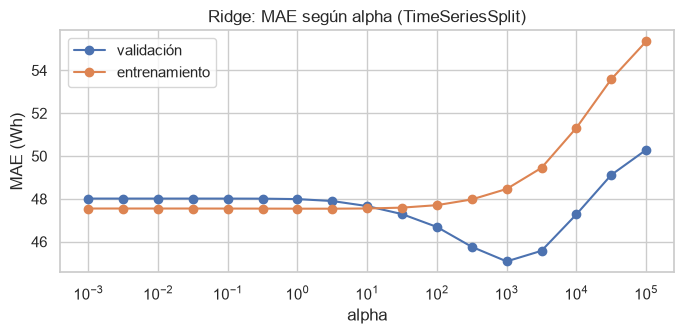

In [4]:
ridge = TransformedTargetRegressor(
    regressor=Pipeline([('prep', preprocesador), ('modelo', Ridge())]),
    func=np.log1p, inverse_func=np.expm1)

grid_ridge = GridSearchCV(ridge, {'regressor__modelo__alpha': np.logspace(-3, 5, 17)},
                          cv=tscv, scoring='neg_mean_absolute_error', return_train_score=True)
t0 = time.time(); grid_ridge.fit(X_train, y_train)
print(f'Tiempo: {time.time() - t0:.1f} s')
print('Mejor alpha:', grid_ridge.best_params_['regressor__modelo__alpha'])
print(f'MAE validación cruzada: {-grid_ridge.best_score_:.2f} Wh')

cv_ridge = pd.DataFrame(grid_ridge.cv_results_)
ax = plt.figure(figsize=(7, 3.5)).gca()
ax.semilogx(cv_ridge['param_regressor__modelo__alpha'].astype(float), -cv_ridge['mean_test_score'], marker='o', label='validación')
ax.semilogx(cv_ridge['param_regressor__modelo__alpha'].astype(float), -cv_ridge['mean_train_score'], marker='o', label='entrenamiento')
ax.set_xlabel('alpha'); ax.set_ylabel('MAE (Wh)'); ax.set_title('Ridge: MAE según alpha (TimeSeriesSplit)'); ax.legend()
plt.tight_layout(); plt.show()

## 4. Modelo 2 — Random Forest

La relación entre consumo y ambiente no tiene por qué ser lineal: por ejemplo, el efecto de la temperatura de la
cocina depende de la hora. Un **Random Forest** (conjunto de árboles de decisión) captura no linealidades e
interacciones sin especificarlas a mano, y sirve para medir cuánto gana el problema con un modelo más flexible.

Parámetros:
- `n_estimators=200`: suficientes árboles para que el promedio sea estable sin un costo de cómputo alto.
- `max_features=0.5`: cada división considera la mitad de las variables, lo que reduce la correlación entre árboles.
- Se buscan `max_depth` (profundidad máxima) y `min_samples_leaf` (mínimo de registros por hoja), que controlan el
  **sobreajuste**: árboles muy profundos memorizan el ruido de cada 10 minutos.
- `random_state=42` para reproducibilidad.

El escalado no es necesario para árboles (no cambia sus divisiones), pero se mantiene el mismo preprocesador para que
ambos modelos reciban exactamente los mismos datos.

In [5]:
rf = TransformedTargetRegressor(
    regressor=Pipeline([('prep', preprocesador),
                        ('modelo', RandomForestRegressor(n_estimators=200, max_features=0.5,
                                                         random_state=RANDOM_STATE, n_jobs=-1))]),
    func=np.log1p, inverse_func=np.expm1)

grid_rf = GridSearchCV(rf, {'regressor__modelo__max_depth': [4, 8, 16],
                            'regressor__modelo__min_samples_leaf': [10, 50]},
                       cv=tscv, scoring='neg_mean_absolute_error', return_train_score=True)
t0 = time.time(); grid_rf.fit(X_train, y_train)
print(f'Tiempo: {time.time() - t0:.1f} s')
print('Mejores parámetros:', grid_rf.best_params_)
print(f'MAE validación cruzada: {-grid_rf.best_score_:.2f} Wh')

(pd.DataFrame(grid_rf.cv_results_)
   [['param_regressor__modelo__max_depth', 'param_regressor__modelo__min_samples_leaf',
     'mean_train_score', 'mean_test_score', 'std_test_score']]
   .assign(mean_train_score=lambda d: -d.mean_train_score, mean_test_score=lambda d: -d.mean_test_score)
   .rename(columns={'param_regressor__modelo__max_depth': 'max_depth',
                    'param_regressor__modelo__min_samples_leaf': 'min_samples_leaf',
                    'mean_train_score': 'MAE_train', 'mean_test_score': 'MAE_validación',
                    'std_test_score': 'desv_validación'})
   .sort_values('MAE_validación'))

Tiempo: 21.7 s
Mejores parámetros: {'regressor__modelo__max_depth': 16, 'regressor__modelo__min_samples_leaf': 50}
MAE validación cruzada: 45.56 Wh


,max_depth,min_samples_leaf,MAE_train,MAE_validación,desv_validación
5,16,50,40.738,45.557,3.877
0,4,10,44.795,45.578,3.791
3,8,50,41.690,45.580,4.113
1,4,50,45.638,45.675,3.714
2,8,10,36.922,46.266,4.819
4,16,10,30.808,46.874,5.038


## 5. Evaluación en el conjunto de prueba

Cada modelo final (ya reentrenado por `GridSearchCV` con todo el entrenamiento y sus mejores parámetros) se evalúa
**una sola vez** en el periodo de prueba, que no se usó para ninguna decisión. Se muestra también el MAE de
validación cruzada: si el de prueba es mucho peor, el modelo no generaliza bien al periodo futuro.

In [6]:
modelos = {'Ridge': grid_ridge, 'Random Forest': grid_rf}
pred = {'Línea base': pred_base}
pred.update({n: g.predict(X_test) for n, g in modelos.items()})

tabla = pd.DataFrame({n: metricas(y_test, p) for n, p in pred.items()}).T
tabla['MAE_train'] = [np.nan] + [mean_absolute_error(y_train, g.predict(X_train)) for g in modelos.values()]
tabla['MAE_validación_cruzada'] = [np.nan] + [-g.best_score_ for g in modelos.values()]
tabla['Mejora MAE vs. base'] = 1 - tabla['MAE'] / tabla.loc['Línea base', 'MAE']
tabla

,MAE,RMSE,R2,MAE_train,MAE_validación_cruzada,Mejora MAE vs. base
Línea base,46.947,85.482,0.118,NaN,NaN,0.000
Ridge,40.862,86.144,0.105,45.014,45.079,0.130
Random Forest,51.535,86.663,0.094,37.181,45.557,-0.098


## 6. Predicciones

### 6.1 Muestra de predicciones

In [11]:
res = test[['date', 'Appliances']].copy()
for n, p in pred.items():
    res[f'pred_{n}'] = np.round(p, 1)
res.to_csv('data/predicciones_test.csv', index=False)
res.iloc[::400].head(10)

,date,Appliances,pred_Línea base,pred_Ridge,pred_Random Forest
0,2016-04-30 08:20:00,370,102.000,63.500,68.200
400,2016-05-03 03:00:00,50,47.200,49.500,55.000
800,2016-05-05 21:40:00,50,101.400,62.800,80.400
1200,2016-05-08 16:20:00,60,116.400,116.800,132.200
1600,2016-05-11 11:00:00,50,135.200,121.000,169.900
2000,2016-05-14 05:40:00,60,50.700,43.300,68.200
2400,2016-05-17 00:20:00,50,52.700,56.100,61.900
2800,2016-05-19 19:00:00,70,149.700,80.600,152.600
3200,2016-05-22 13:40:00,100,128.300,143.100,146.100
3600,2016-05-25 08:20:00,60,102.000,77.100,99.700


### 6.2 Una semana del periodo de prueba

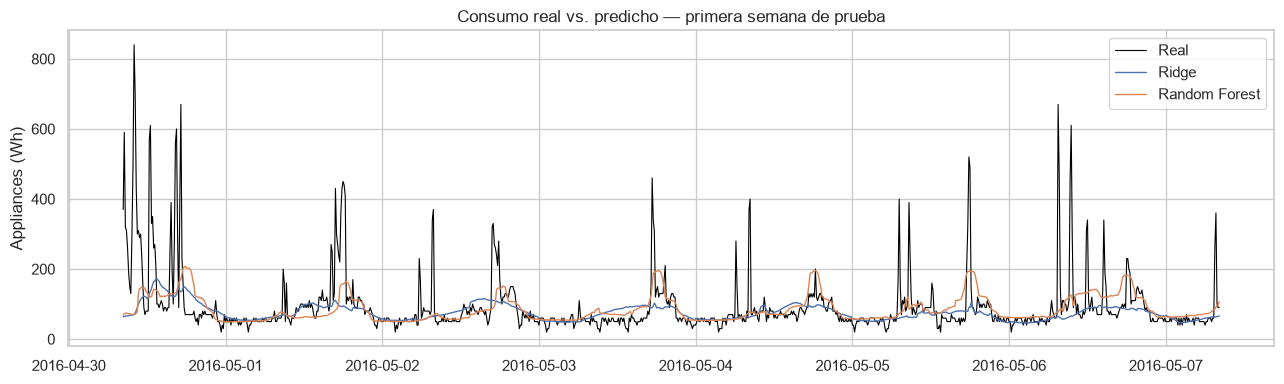

In [8]:
semana = res['date'] < res['date'].min() + pd.Timedelta(days=7)
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(res.loc[semana, 'date'], res.loc[semana, 'Appliances'], lw=0.8, color='black', label='Real')
for n in modelos:
    ax.plot(res.loc[semana, 'date'], res.loc[semana, f'pred_{n}'], lw=1, label=n)
ax.set_title('Consumo real vs. predicho — primera semana de prueba'); ax.set_ylabel('Appliances (Wh)'); ax.legend()
plt.tight_layout(); plt.show()

### 6.3 Real vs. predicho

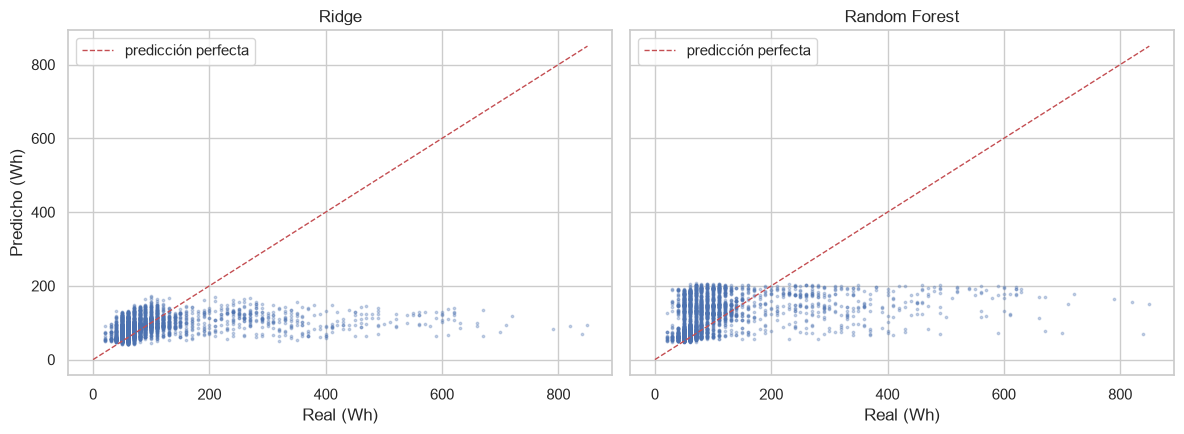

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, n in zip(axes, modelos):
    ax.scatter(y_test, pred[n], s=3, alpha=0.3)
    lim = [0, y_test.max()]
    ax.plot(lim, lim, 'r--', lw=1, label='predicción perfecta')
    ax.set_title(n); ax.set_xlabel('Real (Wh)'); ax.legend()
axes[0].set_ylabel('Predicho (Wh)')
plt.tight_layout(); plt.show()

### 6.4 Errores por hora del día y por nivel de consumo

Se revisa **dónde** se equivoca el modelo: el error medio con signo (real − predicho) indica sesgo; un valor positivo
significa que el modelo **subestima**.

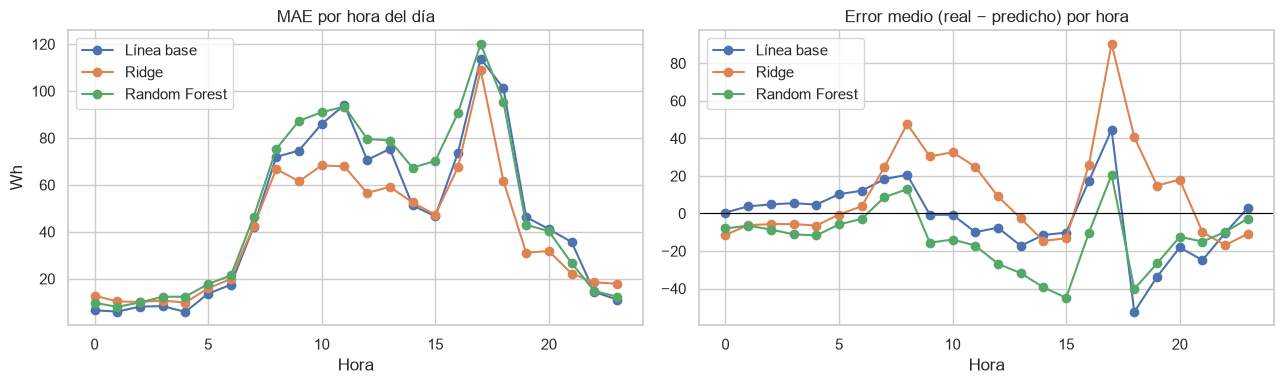

Registros por nivel: {'≤100 Wh': 3120, '100–200 Wh': 502, '>200 Wh': 325}


Error medio (Wh)                         MAE (Wh)          \
                 Línea base   Ridge Random Forest Línea base   Ridge   
Appliances                                                             
≤100 Wh             -25.000 -16.400       -35.900     30.100  20.400   
100–200 Wh           -8.500  27.500       -14.500     34.600  33.600   
>200 Wh             227.300 248.500       205.000    227.300 248.500   

                          
           Random Forest  
Appliances                
≤100 Wh           38.000  
100–200 Wh        36.400  
>200 Wh          205.000

In [10]:
hora = res['date'].dt.hour
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for n in pred:
    err = res['Appliances'] - pred[n]
    err.abs().groupby(hora).mean().plot(ax=axes[0], marker='o', label=n)
    err.groupby(hora).mean().plot(ax=axes[1], marker='o', label=n)
axes[0].set_title('MAE por hora del día'); axes[0].set_ylabel('Wh')
axes[1].set_title('Error medio (real − predicho) por hora'); axes[1].axhline(0, color='black', lw=0.8)
for ax in axes: ax.set_xlabel('Hora'); ax.legend()
plt.tight_layout(); plt.show()

nivel = pd.cut(res['Appliances'], [0, 100, 200, np.inf], labels=['≤100 Wh', '100–200 Wh', '>200 Wh'])
err = pd.DataFrame({n: res['Appliances'] - p for n, p in pred.items()})
print('Registros por nivel:', nivel.value_counts().sort_index().to_dict())
pd.concat({'Error medio (Wh)': err.groupby(nivel, observed=True).mean(),
           'MAE (Wh)': err.abs().groupby(nivel, observed=True).mean()}, axis=1).round(1)

## 7. Interpretación de los modelos

### 7.1 Coeficientes de Ridge
Como las variables están estandarizadas y el objetivo está en logaritmo, cada coeficiente indica aproximadamente el
cambio relativo del consumo cuando la variable aumenta una desviación estándar (manteniendo las demás fijas). Por la
colinealidad entre temperaturas, los coeficientes individuales deben leerse con cautela.

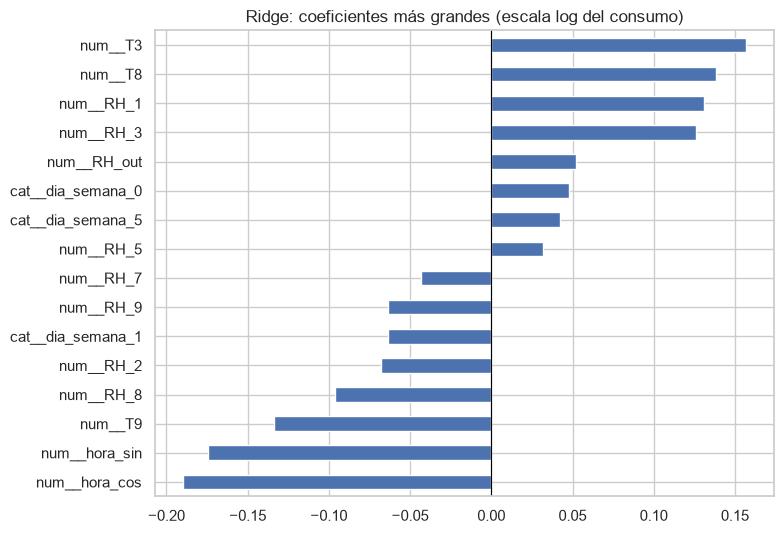

In [12]:
mejor_ridge = grid_ridge.best_estimator_.regressor_
coef = pd.Series(mejor_ridge.named_steps['modelo'].coef_,
                 index=mejor_ridge.named_steps['prep'].get_feature_names_out()).sort_values()
top = pd.concat([coef.head(8), coef.tail(8)])
top.plot(kind='barh', figsize=(8, 5.5), title='Ridge: coeficientes más grandes (escala log del consumo)')
plt.axvline(0, color='black', lw=0.8); plt.tight_layout(); plt.show()

### 7.2 Importancia por permutación
Se mide cuánto empeora el MAE en **prueba** al desordenar al azar cada variable. Es comparable entre modelos y
trata `dia_semana` como una sola variable.

,Ridge,Random Forest
hora_sin,5.020,5.900
hora_cos,5.930,5.390
RH_3,1.020,0.260
RH_9,1.700,0.140
T3,2.520,0.130
RH_out,0.490,0.100
T4,-0.170,0.060
RH_7,0.870,0.040
T9,3.860,0.030
RH_1,4.160,0.020


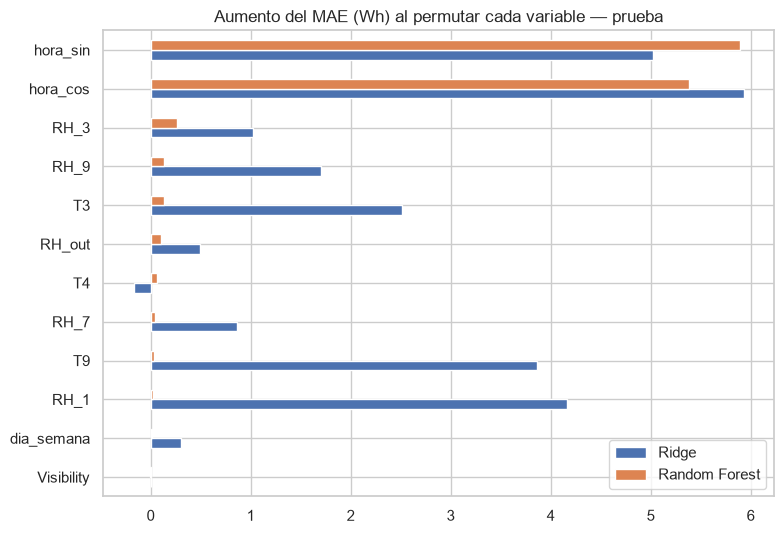

In [13]:
imp = {}
for n, g in modelos.items():
    r = permutation_importance(g, X_test, y_test, scoring='neg_mean_absolute_error',
                               n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
    imp[n] = pd.Series(r.importances_mean, index=FEATURES)
imp = pd.DataFrame(imp).sort_values('Random Forest', ascending=False)
display(imp.head(12).round(2))
imp.head(12).iloc[::-1].plot(kind='barh', figsize=(8, 5.5),
                             title='Aumento del MAE (Wh) al permutar cada variable — prueba')
plt.tight_layout(); plt.show()

## 8. Resumen automático

Esta celda resume los números del modelo con mejor MAE de **validación cruzada** (no se elige por el test, para no
usar el periodo de prueba en las decisiones).

In [14]:
mejor = min(modelos, key=lambda n: -modelos[n].best_score_)
m = tabla.loc[mejor]
print(f'Modelo seleccionado por validación cruzada: {mejor}')
print(f"  Parámetros: {modelos[mejor].best_params_}")
print(f"  Prueba → MAE {m['MAE']:.1f} Wh | RMSE {m['RMSE']:.1f} Wh | R² {m['R2']:.3f}")
print(f"  Mejora de MAE frente a la línea base: {m['Mejora MAE vs. base']:.1%}")
print(f"  Consumo medio real en prueba: {y_test.mean():.1f} Wh")

Modelo seleccionado por validación cruzada: Ridge
  Parámetros: {'regressor__modelo__alpha': np.float64(1000.0)}
  Prueba → MAE 40.9 Wh | RMSE 86.1 Wh | R² 0.105
  Mejora de MAE frente a la línea base: 13.0%
  Consumo medio real en prueba: 96.4 Wh


## 9. Conclusiones de la semana 13

1. **Modelo seleccionado.** Por validación cruzada temporal se eligió la **regresión Ridge (alpha = 1000)**, con un
   MAE de validación de 45,1 Wh frente a 45,6 Wh del Random Forest. En prueba obtuvo **MAE = 40,9 Wh**, un 13 % menos
   que la línea base de media por hora (46,9 Wh); RMSE = 86,1 Wh y R² = 0,105.
2. **MAE mejora, RMSE y R² no.** Ridge queda ligeramente por debajo de la línea base en RMSE (85,5 Wh) y R² (0,118).
   Al entrenar sobre `log1p`, el modelo predice valores cercanos al consumo típico (mediana de 60 Wh): reduce mucho el
   error en los registros de bajo consumo (MAE 20,4 Wh frente a 30,1 Wh en registros ≤ 100 Wh), pero **subestima los
   picos**. Los 325 registros de prueba mayores a 200 Wh (8 %) tienen un error medio de +248 Wh y concentran cerca del
   89 % del error cuadrático, que es lo que miden el RMSE y el R².
3. **Random Forest no generaliza al periodo futuro.** Tiene un MAE de entrenamiento de 37,2 Wh y de validación de
   45,6 Wh, pero en prueba sube a 51,5 Wh, peor que la línea base. El periodo de prueba es más cálido (16 % de sus
   registros tienen `T6` por encima del máximo observado en entrenamiento) y los árboles no extrapolan fuera de los
   rangos que conocen. Además sobrestima los consumos bajos (error medio de −35,9 Wh en registros ≤ 100 Wh).
4. **Qué variables importan.** En ambos modelos la **hora del día** es, por mucho, la variable más importante: al
   permutarla, el MAE empeora unos 5–6 Wh por cada componente. Las variables ambientales aportan poco (en Ridge,
   `RH_1`, `T9` y `T3` son las que más aportan, con menos de 4,2 Wh) y el día de la semana casi nada.
5. **Respuesta parcial a la pregunta de investigación.** Con variables ambientales y de calendario, y evaluando en un
   periodo futuro, se explica alrededor del 10 % de la variabilidad del consumo. El consumo depende sobre todo de
   acciones de los ocupantes (encender el horno o la lavadora) que estos sensores no registran directamente.
6. **Limitaciones y siguientes pasos.** Es una sola vivienda durante 4,5 meses, con cambio de estación entre
   entrenamiento y prueba; no se usaron rezagos del propio consumo, que cambiarían el problema a pronóstico
   autorregresivo. En la semana 14 se aplicará el clustering y se profundizará en la evaluación e interpretación.